# Customising a simulation

Three things decide what a simulation produces:

| | what | how to change it |
|---|---|---|
| `Electrodes` | where the electrodes sit, which device records | presets, your own list, YAML |
| `Subject` | the person | fields, `Subject.random(seed)` |
| `SimParams` | the model's constants, one block per step | `SimParams().replace(...)` |

Needs `pip install myogen[examples]` (matplotlib).

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np

import myogen as mg

motion = mg.example_motion(duration=3.0, fs=100)

def rms(recording):
    return np.sqrt((recording.emg ** 2).mean(0))

## Electrodes

Each electrode is bipolar and placed anatomically: `angle_deg` around the forearm (0 radial, +90 dorsal over the extensors, -90 palmar over the flexors), `position_cm` from the elbow, `ied_mm` between the poles and `orientation_deg` of the pole axis (0 = along the fibres). The `raw` device gives mV at `fs`.

In [2]:
electrodes = mg.Electrodes([
    mg.Electrode(angle_deg=90, position_cm=7, name="extensors"),
    mg.Electrode(angle_deg=-90, position_cm=7, name="flexors"),
    mg.Electrode(angle_deg=90, position_cm=7, orientation_deg=90, name="extensors, across"),
], device="raw")
recording = mg.Simulator(electrodes).run(motion)
for name, value in zip(electrodes.names, rms(recording)):
    print(f"{name:20s} {value * 1000:6.1f} uV RMS")

/home/marcos-oriol/Documents/ETHRC/control/BRI-ForearmEMGWorldModelDataset/tools/myogen/.venv/lib/python3.12/site-p
ackages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

extensors             305.2 uV RMS
flexors               230.2 uV RMS
extensors, across     225.1 uV RMS


Electrode sets are device profiles: save them as YAML, edit them, and load them back (or pass the file to `myogen simulate --electrodes`).

In [4]:
electrodes.save("my_electrodes.yml")
print(open("my_electrodes.yml").read()[:400])

electrodes:
- angle_deg: 90
  position_cm: 7
  ied_mm: 20.0
  orientation_deg: 0.0
  name: extensors
- angle_deg: -90
  position_cm: 7
  ied_mm: 20.0
  orientation_deg: 0.0
  name: flexors
- angle_deg: 90
  position_cm: 7
  ied_mm: 20.0
  orientation_deg: 90
  name: extensors, across
device: raw
fs: 2000.0
gain: 1.0
noise_uv: 1.5
mains_hz: 50.0
mains_uv: 2.0
motion_artifact: 1.0
channel_gain: null


## Subjects

`Subject()` is an average adult. `Subject.random(seed)` draws one from population ranges (forearm size, fat, muscle sizes, effort, ...); `amputee=True` gives a transradial residual limb without intrinsic hand muscles.

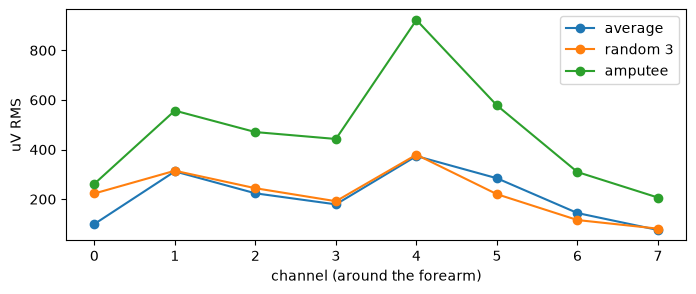

In [3]:
subjects = {"average": mg.Subject(), "random 3": mg.Subject.random(3),
            "amputee": mg.Subject.random(3, amputee=True)}
ring = mg.Electrodes.ring(n=8, position_cm=5, device="raw")
fig, ax = plt.subplots(figsize=(8, 3))
for name, subject in subjects.items():
    ax.plot(rms(mg.Simulator(ring, subject=subject).run(motion)) * 1000, "o-", label=name)
ax.set_xlabel("channel (around the forearm)")
ax.set_ylabel("uV RMS")
ax.legend()

## Model parameters

Every constant of the simulation is in `myogen.params`, one frozen dataclass per step. `replace` returns a copy with some fields changed. Here: a larger EMG decay distance makes every electrode see muscles from further away, so neighbouring channels become more alike.

In [4]:
params = mg.SimParams()
print(params.emg)

wide = params.replace(emg={"decay_mm": 20.0})
for label, p in [("decay 12 mm", params), ("decay 20 mm", wide)]:
    emg = mg.Simulator(ring, params=p).run(motion).emg
    neighbours = np.mean([np.corrcoef(np.abs(emg[:, c]), np.abs(emg[:, (c + 1) % 8]))[0, 1] for c in range(8)])
    print(f"{label}: neighbour envelope correlation {neighbours:.2f}")

EMGParams(motor_units=MotorUnitParams(units_per_newton=0.25, min_units=20, max_units=200, recruitment_max=0.7, recruitment_range=30.0, amplitude_range=10.0, min_rate_hz=8.0, rate_gain_hz=40.0, peak_rate_hz=35.0, isi_cv=0.15, common_drive=0.05, common_drive_hz=2.0, waveform='biphasic', volume_conductor=VolumeConductorParams(sigma_muscle_radial=0.1, sigma_muscle_axial=0.5, sigma_fat=0.05, sigma_skin=1.0, sigma_bone=0.02, skin_mm=1.0, bone_radius_mm=5.0, conduction_velocity=4.0, fibre_length_mm=60.0, tendon_spread_mm=6.0, iap_lambda=1.0, fibre_diameter_um=55.0, sigma_intracellular=1.01, territory_mm=2.0, endplate_spread_mm=5.0, electrode_radius_mm=2.5, depths_mm=(0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10, 12, 14, 17, 20, 24, 28, 33), angle_step_deg=2.5, max_distance_mm=200.0, distance_step_mm=2.0, half_window_ms=25.0, grid_mm=0.5, window_mm=512.0, angular_orders=64, n_basis=10), width_ms=1.0, width_per_mm=0.25, bands_ms=(0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0)), decay_mm=12.0, conduction_velocity=4.

decay 12 mm: neighbour envelope correlation 0.39


decay 20 mm: neighbour envelope correlation 0.57


## Matching a real device

`calibrate` fits the device settings of an electrode profile (gain, noise, Otto Bock smoothing, optionally the armband rotation) to real recordings of known movements. Noise can only be measured where the muscles rest, so the recording needs some labelled rest (`HandMotion.rest`). Here a simulated recording with a different gain and noise stands in for the real one.

In [5]:
from myogen.inputs.motion import REST_POSTURE
from myogen.simulation.musculoskeletal import HAND_JOINTS

relaxed = np.tile([REST_POSTURE[j] for j in HAND_JOINTS], (200, 1))       # 2 s of a relaxed hand
session = mg.HandMotion(np.vstack([relaxed, motion.angles]), motion.fs,
                        rest=np.r_[np.ones(200, bool), np.zeros(len(motion.angles), bool)])

sim = mg.Simulator(mg.Electrodes.otto_bock())
truth = dataclasses.replace(mg.Electrodes.otto_bock(), gain=1.7, noise_uv=3.0)
real = sim.record(sim.simulate(session), truth).emg

cal = mg.calibrate(sim, [session], [real])
print(cal)
print("fitted gain:", round(cal.electrodes.gain, 2), " noise_uv:", round(cal.electrodes.noise_uv, 2))

statistic                     real    before     after
amplitude                    1.159    0.6811     1.159
rest_floor                 0.02129   0.01257   0.02129
autocorr_50ms               0.9202    0.9194    0.9202
autocorr_200ms              0.6697    0.6639    0.6697
neighbour_correlation       0.6846    0.6822    0.6846
rest_move_ratio            0.03365   0.03381   0.03365
channel_correlation              -    0.9995    0.9995
fitted: gain 1 -> 1.7, noise_uv 1.5 -> 3, smooth_hz 4.5 -> 4.5
fitted gain: 1.7  noise_uv: 3.0
